Zip         : archive.zip
Kelas       : ['apple fruit', 'banana fruit', 'cherry fruit', 'chickoo fruit', 'grapes fruit', 'kiwi fruit', 'mango fruit', 'orange fruit', 'strawberry fruit']
Jumlah citra: 359


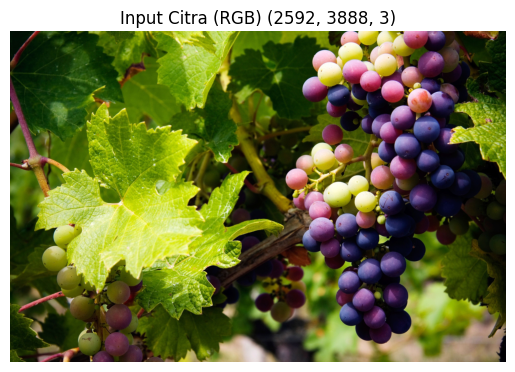

In [ ]:
import os, glob, zipfile
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

KSIZE = 15               # kernel median (harus ganjil)
OUT_DIR = "hasil"       # semua output disimpan di sini

# Unzip dataset. Ganti ZIP_PATH sesuai lokasi zip-mu
ZIP_PATH = "archive.zip"
EXTRACT_DIR = "dataset"

assert os.path.exists(ZIP_PATH), f"Zip tidak ditemukan: {ZIP_PATH} (folder kerja: {os.getcwd()})"
os.makedirs(EXTRACT_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(EXTRACT_DIR)

# Cari folder 'images' (kalau tidak ada, pakai folder hasil extract)
ROOT = next((d for d, _, _ in os.walk(EXTRACT_DIR) if os.path.basename(d).lower() == "images"), EXTRACT_DIR)

paths = sorted(p for p in glob.glob(f"{ROOT}/*/*") if p.lower().endswith((".jpg", ".jpeg", ".png")))
print("Zip         :", ZIP_PATH)
print("Kelas       :", sorted(os.listdir(ROOT)))
print("Jumlah citra:", len(paths))

# Tampilkan contoh citra input
sample = cv2.cvtColor(
    cv2.imread("/content/dataset/images/grapes fruit/Image_8.jpg"),
    cv2.COLOR_BGR2RGB
)
plt.imshow(sample)
plt.title(f"Input Citra (RGB) {sample.shape}")
plt.axis("off")
plt.show()

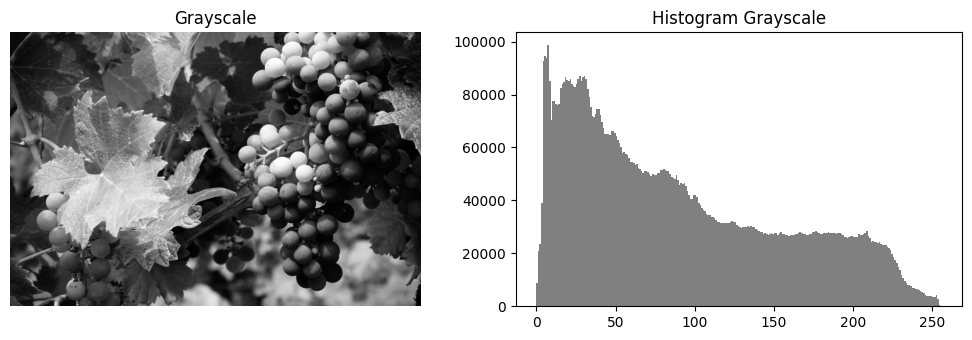

In [ ]:
def load_gray(p):
    """Baca citra -> grayscale (ukuran asli, tanpa resize)."""
    img = cv2.imread(p)
    return None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def tampil(img, judul):
    """Tampilkan citra + histogramnya."""
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].imshow(img, cmap="gray", vmin=0, vmax=255)
    ax[0].set_title(judul)
    ax[0].axis("off")
    ax[1].hist(img.ravel(), bins=256, range=(0, 256), color="gray")
    ax[1].set_title(f"Histogram {judul}")
    plt.tight_layout()
    plt.show()

gray = load_gray("/content/dataset/images/grapes fruit/Image_8.jpg")
tampil(gray, "Grayscale")

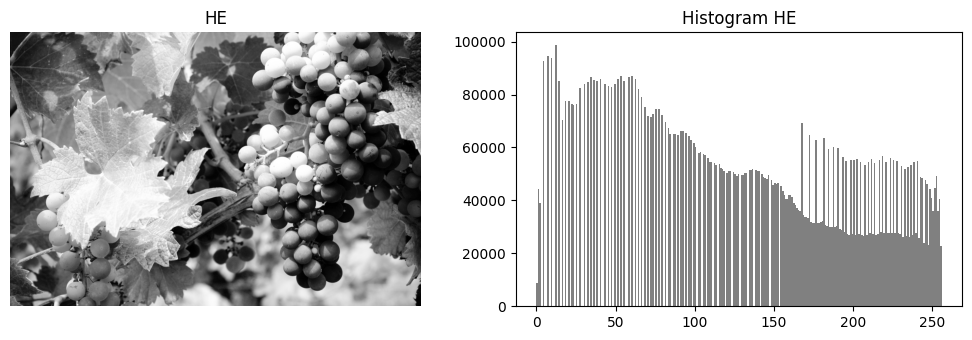

In [ ]:
def hist_eq(g):
    return cv2.equalizeHist(g)

tampil(hist_eq(gray), "HE")

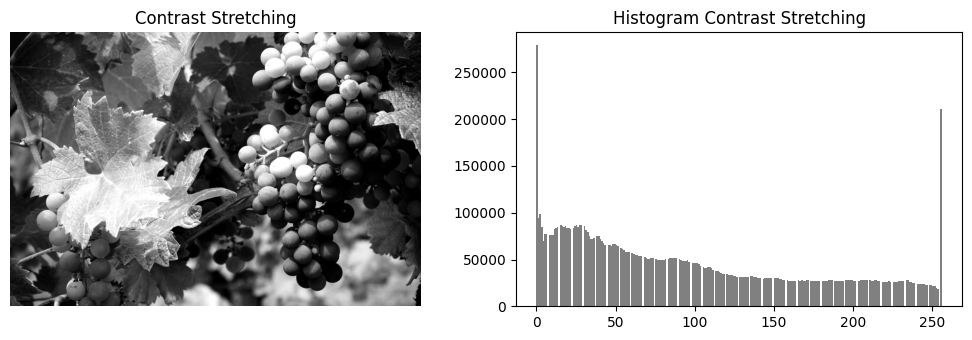

In [ ]:
def contrast_stretch(g, low=2, high=98):
    """Linear stretching ke 0-255 berdasarkan persentil (tahan outlier)."""
    lo, hi = np.percentile(g, (low, high))
    if hi <= lo:
        return g.copy()
    out = np.clip((g.astype(np.float32) - lo) / (hi - lo), 0, 1) * 255
    return out.astype(np.uint8)

tampil(contrast_stretch(gray), "Contrast Stretching")

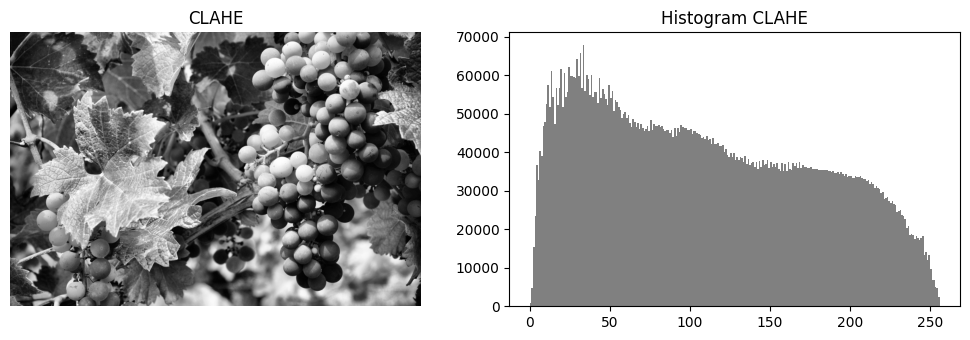

In [ ]:
_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def clahe(g):
    return _clahe.apply(g)

tampil(clahe(gray), "CLAHE")

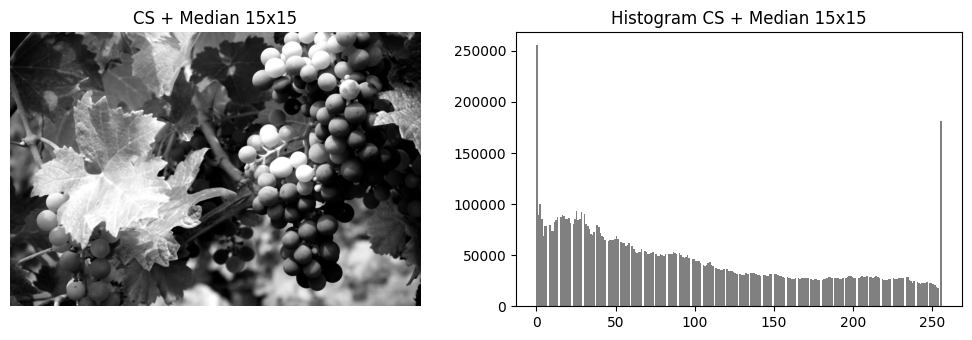

In [ ]:
def apply_filter(g):
    return cv2.medianBlur(g, KSIZE)

tampil(apply_filter(contrast_stretch(gray)), f"CS + Median {KSIZE}x{KSIZE}")

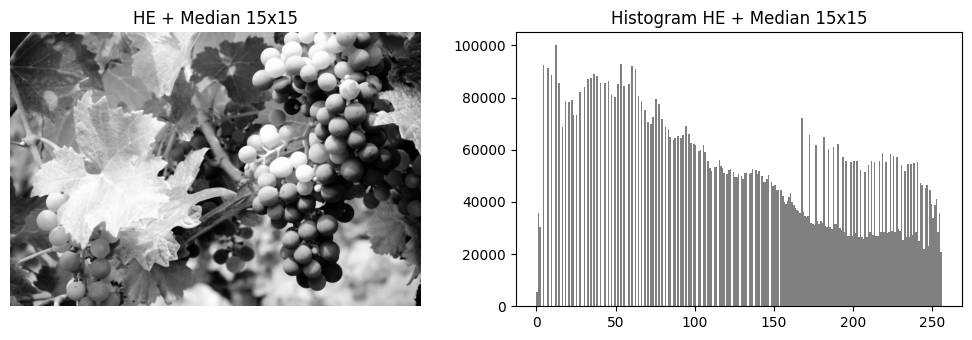

In [ ]:
tampil(apply_filter(hist_eq(gray)), f"HE + Median {KSIZE}x{KSIZE}")

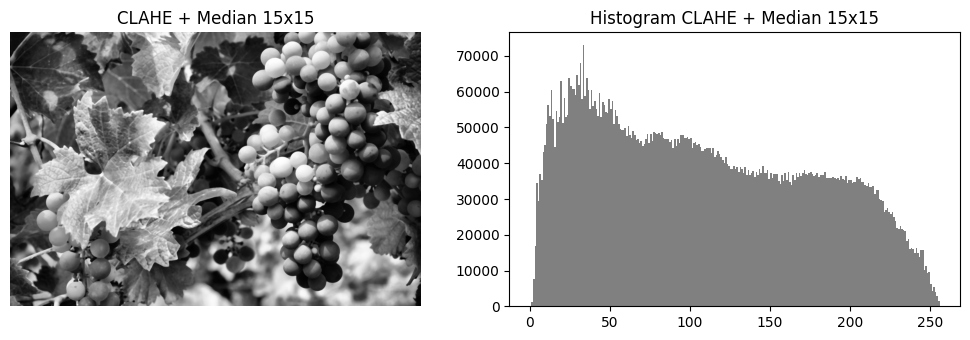

In [ ]:
tampil(apply_filter(clahe(gray)), f"CLAHE + Median {KSIZE}x{KSIZE}")

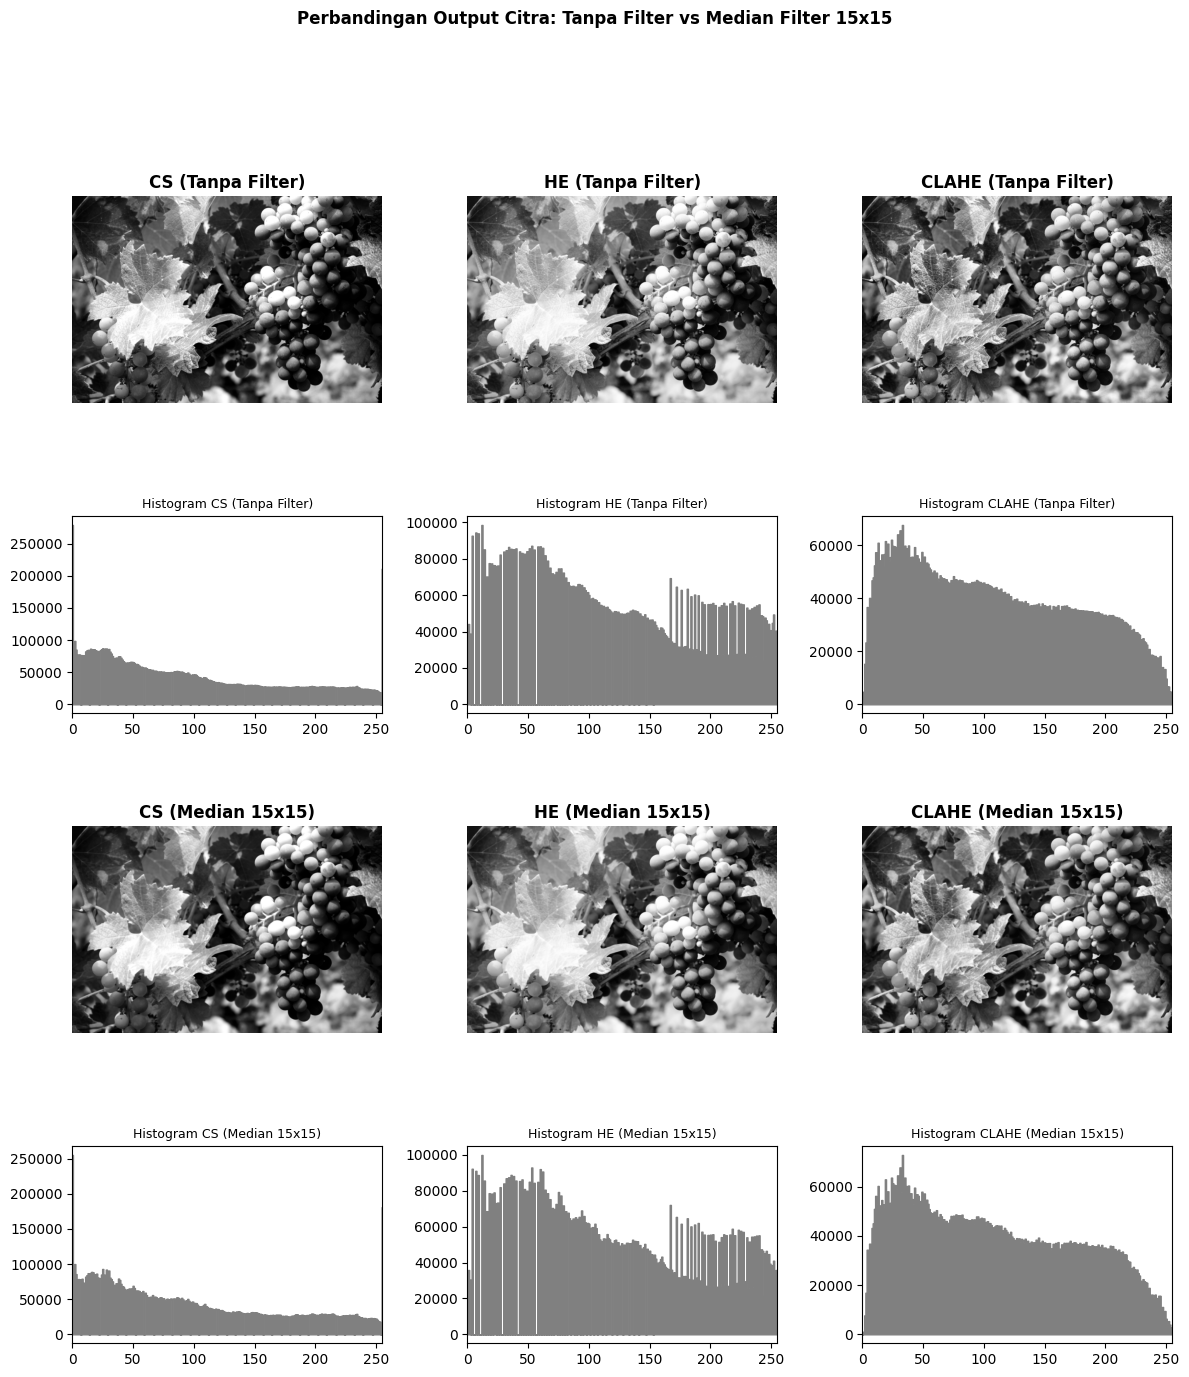

In [ ]:
ENHANCEMENTS = {"CS": contrast_stretch, "HE": hist_eq, "CLAHE": clahe}
TAMPIL_SKALA = 3

def hitung(g):
    """Hitung enhancement dan enhancement+filter sekali saja per citra."""
    out = {}
    for nama, fn in ENHANCEMENTS.items():
        enh = fn(g)
        out[nama] = (enh, apply_filter(enh))
    return out

def panel6(g, judul=None, hasil=None):
    """Panel 4x3: gambar + histogramnya. Baris 1-2 = tanpa filter, baris 3-4 = Median."""
    if hasil is None:
        hasil = hitung(g)
    fig, axes = plt.subplots(4, 3, figsize=(12, 14), gridspec_kw={"height_ratios": [3, 1.3, 3, 1.3]})
    for c, (nama, (enh, flt)) in enumerate(hasil.items()):
        for r, (im, ket) in enumerate([(enh, "Tanpa Filter"), (flt, f"Median {KSIZE}x{KSIZE}")]):
            ax_img, ax_his = axes[2 * r, c], axes[2 * r + 1, c]
            kecil = im if TAMPIL_SKALA == 1 else cv2.resize(
                im, None, fx=1 / TAMPIL_SKALA, fy=1 / TAMPIL_SKALA, interpolation=cv2.INTER_AREA)
            ax_img.imshow(kecil, cmap="gray", vmin=0, vmax=255)
            ax_img.set_title(f"{nama} ({ket})", fontweight="bold")
            ax_img.axis("off")
            ax_his.fill_between(range(256), np.bincount(im.ravel(), minlength=256), step="mid", color="gray")
            ax_his.set_xlim(0, 255)
            ax_his.set_title(f"Histogram {nama} ({ket})", fontsize=9)
    fig.suptitle(judul or f"Perbandingan Output Citra: Tanpa Filter vs Median Filter {KSIZE}x{KSIZE}",
                 fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    return fig

panel6(gray)
plt.show()

In [34]:
from tqdm.auto import tqdm

MAX_PER_KELAS = None   # mis. 5 untuk tes cepat; None = semua citra
TAMPIL_PATH = "/content/dataset/images/grapes fruit/Image_8.jpg"   # hanya citra ini yang DITAMPILKAN

def mse(a, b):
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)

def psnr(a, b):
    m = mse(a, b)
    return np.inf if m == 0 else 10 * np.log10(255.0 ** 2 / m)

# Urutan baris tabel: tiga enhancement, lalu tiga enhancement+median
URUT = list(ENHANCEMENTS) + [f"{n}+Median" for n in ENHANCEMENTS]

# Pilih citra yang diproses (opsional dibatasi per kelas)
daftar, hitung_kelas = [], {}
for p in paths:
    k = os.path.basename(os.path.dirname(p))
    hitung_kelas[k] = hitung_kelas.get(k, 0) + 1
    if MAX_PER_KELAS is None or hitung_kelas[k] <= MAX_PER_KELAS:
        daftar.append(p)

rows = []
for p in tqdm(daftar):
    g = load_gray(p)
    if g is None:
        continue
    kelas = os.path.basename(os.path.dirname(p))
    nama_file = os.path.splitext(os.path.basename(p))[0]

    hasil = hitung(g)   # sekali saja per citra
    for nama, (enh, flt) in hasil.items():
        for metode, out in [(nama, enh), (f"{nama}+Median", flt)]:
            rows.append(dict(Kelas=kelas, Citra=os.path.basename(p), Metode=metode,
                             MSE=mse(g, out), PSNR=psnr(g, out)))   # selalu vs grayscale

    os.makedirs(f"{OUT_DIR}/{kelas}", exist_ok=True)
    fig = panel6(g, f"{kelas}/{nama_file}  |  Tanpa Filter vs Median {KSIZE}x{KSIZE}", hasil)
    fig.savefig(f"{OUT_DIR}/{kelas}/{nama_file}_interpretasi.png", dpi=100)
    plt.close(fig)

# PSNR=inf (MSE=0) dijadikan NaN
df = pd.DataFrame(rows).replace(np.inf, np.nan)
df.to_csv(f"{OUT_DIR}/mse_psnr_per_citra.csv", index=False)   # satu baris per citra per metode
print("Selesai:", len(daftar), "citra diproses dan disimpan (semua kelas)")

# Tampilkan HANYA citra terpilih
kelas_t = os.path.basename(os.path.dirname(TAMPIL_PATH))
citra_t = os.path.basename(TAMPIL_PATH)
df_t = df[(df["Kelas"] == kelas_t) & (df["Citra"] == citra_t)]

if df_t.empty:
    print(f"Citra '{kelas_t}/{citra_t}' tidak ada di hasil. Cek TAMPIL_PATH (atau MAX_PER_KELAS terlalu kecil).")
else:
    print(f"Hasil {kelas_t}/{citra_t} (dibandingkan dengan grayscale)")
    display(df_t.set_index("Metode")[["MSE", "PSNR"]].round(4).reindex(URUT))

  0%|          | 0/359 [00:00<?, ?it/s]

Selesai: 359 citra diproses dan disimpan (semua kelas)
Hasil grapes fruit/Image_8.jpg (dibandingkan dengan grayscale)


,MSE,PSNR
Metode,,
CS,148.4055,26.4163
HE,1818.2993,15.5341
CLAHE,999.7425,18.1319
CS+Median,172.5013,25.7629
HE+Median,1838.0185,15.4873
CLAHE+Median,992.0294,18.1656


In [35]:
import shutil

zip_out = shutil.make_archive("hasil_UTS", "zip", OUT_DIR)   # hasil_UTS.zip (di luar folder hasil/)
print("Zip dibuat:", os.path.abspath(zip_out), f"({os.path.getsize(zip_out) / 1e6:.1f} MB)")

import os
if os.path.exists(zip_out):
    print(f"File zip SUDAH JADI. Ukuran: {os.path.getsize(zip_out) / 1e6:.1f} MB")
else:
    print("File zip BELUM JADI. Proses zip masih berjalan atau gagal.")

try:
    from google.colab import files          # Colab: download otomatis
    files.download(zip_out)
except ImportError:
    from IPython.display import FileLink    # Jupyter: klik link untuk download
    display(FileLink(zip_out))

Zip dibuat: /content/hasil_UTS.zip (155.6 MB)
File zip SUDAH JADI. Ukuran: 155.6 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>